# Phân tích các câu hỏi về phim

Notebook này dành cho phần phân tích sâu ba câu hỏi không dùng học máy (non-ML) của nhóm: chênh lệch điểm giữa IMDb và TMDB (Q1), sự thay đổi thời lượng phim theo thời gian (Q3) và sự khác biệt về doanh thu giữa các thể loại khi so sánh những phim có ngân sách tương đương (Q4).

## Q1. IMDb và TMDB chấm điểm lệch nhau như thế nào?

**Người phụ trách** · Khang

Khi tra cùng một phim trên IMDb và TMDB, người xem có thể thấy hai điểm khác nhau. Hai điểm thường cách nhau bao nhiêu? Khi so cùng một phim, khán giả trên nền tảng nào thường chấm điểm cao hơn? Câu trả lời có thay đổi theo thể loại phim không? Người tổng hợp đánh giá phim có thể dùng kết quả để quyết định khi nào nên tra cả hai nguồn.

### 1. Chọn phim để so sánh

Một phim cần có đủ điểm từ cả hai nguồn. Nhóm chọn phim theo ba bước.

1. **Kiểm tra mã phim.** Mỗi phim phải có cả mã TMDB và mã IMDb. Nếu một trong hai mã xuất hiện nhiều lần trong CSV gốc, nhóm bỏ tất cả các dòng mang mã lặp đó để tránh đếm trùng hoặc dùng một cặp điểm chưa rõ thuộc phim nào.
2. **Kiểm tra ngày phát hành.** Giữ các tác phẩm có trạng thái đã phát hành (`Released`), có ngày phát hành đọc được và năm phát hành đến hết 2025, như trong notebook khám phá.
3. **Kiểm tra điểm và lượt chấm.** Giữ các cặp điểm trong phạm vi nhóm dùng ở notebook khám phá (TMDB từ 0 đến 10, IMDb từ 1 đến 10) và có người chấm ở cả hai bên. Nhóm đặt mức tối thiểu 10 lượt **trên từng nền tảng** để tránh so sánh những điểm chỉ dựa trên vài lượt chấm. Mục 4 thử lại với mức 100 lượt.

Trong Q1, “phim” là cách gọi gọn các tác phẩm trong mẫu. CSV không có cột phân biệt phim điện ảnh với các loại tác phẩm khác.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "environment.yml").is_file())
columns = [
    "id", "tconst", "status", "release_date", "genres",
    "vote_average", "vote_count", "averageRating", "numVotes",
]
movies = pd.read_csv(
    root / "data/raw/TMDB  IMDB Movies Dataset.csv",
    usecols=columns, low_memory=False, keep_default_na=False, na_values=["", r"\N"],
)

In [2]:
release_year = pd.to_datetime(movies["release_date"], format="%Y-%m-%d", errors="coerce").dt.year
unique_ids = (
    movies["id"].notna() & ~movies["id"].duplicated(keep=False)
    & movies["tconst"].str.strip().fillna("").ne("") & ~movies["tconst"].duplicated(keep=False)
)
valid_scores = movies["vote_average"].between(0, 10) & movies["averageRating"].between(1, 10)
votes = movies[["vote_count", "numVotes"]]
steps = [
    ("Có đủ hai mã, mỗi mã xuất hiện một lần trong CSV", unique_ids),
    ("Trạng thái Released", movies["status"].eq("Released")),
    ("Có năm phát hành đến hết 2025", release_year.le(2025)),
    ("Cặp điểm trong thang và có lượt chấm ở cả hai bên", valid_scores & votes.gt(0).all(axis=1)),
    ("Ít nhất 10 lượt chấm mỗi bên", votes.ge(10).all(axis=1)),
]
keep = pd.Series(True, index=movies.index)
counts = []
for label, condition in steps:
    before = int(keep.sum())
    keep &= condition
    after = int(keep.sum())
    counts.append([label, before, after, before - after])

q1 = movies.loc[keep].copy()
display(pd.DataFrame(counts, columns=["Điều kiện thêm vào", "Trước", "Còn lại", "Loại ở bước này"]))

,Điều kiện thêm vào,Trước,Còn lại,Loại ở bước này
0,"Có đủ hai mã, mỗi mã xuất hiện một lần trong CSV",443656,425189,18467
1,Trạng thái Released,425189,422385,2804
2,Có năm phát hành đến hết 2025,422385,407278,15107
3,Cặp điểm trong thang và có lượt chấm ở cả hai bên,407278,265820,141458
4,Ít nhất 10 lượt chấm mỗi bên,265820,77674,188146


Từ **443.656 dòng** ban đầu, có **77.674 phim** đủ điều kiện so sánh. Mục 2 dùng toàn bộ số phim này, kể cả phim thiếu thể loại.

### 2. Khi so cùng một phim, khán giả trên IMDb hay TMDB thường chấm điểm cao hơn? Hai điểm cách nhau bao nhiêu?

Với mỗi phim, nhóm lấy **điểm TMDB trừ điểm IMDb**. Bảng dưới minh họa bằng hai phim giả định. Ký hiệu Δ đọc là “chênh lệch”.

| Phim | Điểm TMDB | Điểm IMDb | Chênh lệch (Δ) | Khoảng cách giữa hai điểm |
| --- | ---: | ---: | ---: | ---: |
| A | 8 | 7 | +1 | 1 điểm |
| B | 6 | 7 | −1 | 1 điểm |

- **Nền tảng nào thường chấm điểm cao hơn?** Trong ví dụ, phim A có điểm TMDB cao hơn, còn phim B có điểm IMDb cao hơn. Khi đếm, phim có 10 lượt chấm cũng được tính một lần như phim có 10.000 lượt. Trong CSV, điểm của cùng một phim có thể được ghi với số chữ số thập phân khác nhau. Ví dụ, phim *Parasite* có điểm TMDB là 8,515 và điểm IMDb là 8,5. Nếu làm tròn đến một chữ số thập phân, cả hai đều hiện là 8,5. Vì vậy, nhóm so sánh điểm gốc trong CSV và tính *Parasite* vào nhóm phim có điểm TMDB cao hơn.
- **Tính trung bình trên tất cả các phim, nền tảng nào chấm điểm cao hơn và cao hơn bao nhiêu điểm?** Lấy trung bình cột *Chênh lệch*. Ở ví dụ trên, +1 và −1 bù nhau nên chênh lệch trung bình bằng **0 điểm**.
- **Khi tra từng phim, hai điểm cách nhau bao nhiêu?** Lấy trung bình cột *Khoảng cách*. Cả hai phim đều lệch **1 điểm**, nên khoảng cách trung bình bằng **1 điểm**. Trong các bảng kết quả, “TB” viết tắt cho “trung bình”.

Nhóm còn tính khoảng tin cậy 95% để xem chênh lệch trung bình dao động bao nhiêu khi chọn lại phim. Cách tính được giải thích ngay sau kết quả.

In [3]:
import numpy as np
from scipy.stats import bootstrap

def mean_gap_interval(gaps):
    result = bootstrap(
        (gaps.to_numpy(),), np.mean, method="percentile", confidence_level=0.95,
        n_resamples=2000, batch=20, random_state=42,
    )
    return result.confidence_interval

def rating_summary(gaps):
    low, high = mean_gap_interval(gaps)
    return pd.Series({
        "Số phim": gaps.size,
        "TMDB cao hơn (%)": 100 * gaps.gt(0).mean(),
        "Bằng điểm (%)": 100 * gaps.eq(0).mean(),
        "IMDb cao hơn (%)": 100 * gaps.lt(0).mean(),
        "Chênh lệch TB": gaps.mean(),
        "Khoảng cách TB": gaps.abs().mean(),
        "Cận dưới 95%": low,
        "Cận trên 95%": high,
    })

gaps = q1["vote_average"] - q1["averageRating"]
main_result = rating_summary(gaps)
display(main_result.to_frame().T.astype({"Số phim": int}).round(3))

,Số phim,TMDB cao hơn (%),Bằng điểm (%),IMDb cao hơn (%),Chênh lệch TB,Khoảng cách TB,Cận dưới 95%,Cận trên 95%
0,77674,41.924,2.805,55.271,0.006,0.527,0.001,0.011


In [4]:
gap_when_higher = pd.Series({
    "TMDB cao hơn": gaps[gaps > 0].mean(),
    "IMDb cao hơn": -gaps[gaps < 0].mean(),
}, name="Số điểm dẫn trung bình khi bên này cao hơn")
display(gap_when_higher.round(3).to_frame())

,Số điểm dẫn trung bình khi bên này cao hơn
TMDB cao hơn,0.636
IMDb cao hơn,0.471


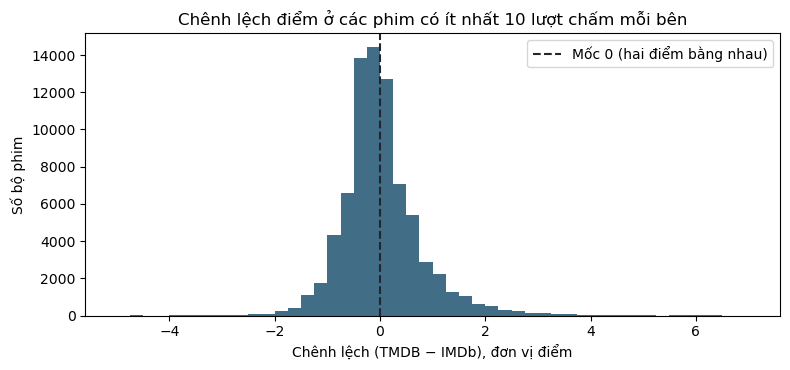

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
edges = np.arange(np.floor(gaps.min()), np.ceil(gaps.max()) + 0.25, 0.25)
ax.hist(gaps, bins=edges, color="#426d87")
ax.axvline(0, color="#20262b", linestyle="--", label="Mốc 0 (hai điểm bằng nhau)")
ax.set(title="Chênh lệch điểm ở các phim có ít nhất 10 lượt chấm mỗi bên",
       xlabel="Chênh lệch (TMDB − IMDb), đơn vị điểm", ylabel="Số bộ phim")
ax.legend()
fig.tight_layout()
plt.show()

**IMDb cao hơn ở 55,27% số phim**, TMDB cao hơn ở 41,92%, còn 2,81% có hai điểm bằng nhau. Khi tra từng phim, hai điểm cách nhau trung bình **0,527 điểm**.

Vậy tại sao khi tính trung bình cả mẫu, TMDB lại nhỉnh hơn **0,006 điểm**? Ở những phim IMDb cao hơn, IMDb dẫn trung bình **0,471 điểm**. TMDB dẫn ở ít phim hơn, nhưng mỗi lần dẫn thì cách biệt trung bình lớn hơn, **0,636 điểm**. Hai phía gần như bù nhau.

**Khoảng tin cậy 95% ở đây nói về số trung bình 0,006 điểm.** Hãy hình dung chọn ngẫu nhiên 77.674 phim từ mẫu hiện có. Một phim có thể được chọn nhiều lần và mỗi lần đều dùng cả hai điểm của phim đó. Nhóm tính lại chênh lệch trung bình, rồi lặp cách chọn này để có 2.000 kết quả. Sau khi xếp chúng từ thấp đến cao và bỏ 2,5% ở mỗi đầu, phần giữa trải từ **+0,001 đến +0,011 điểm**. Đó là cách tính *bootstrap*. Cả hai đầu đều rất gần 0 trên thang điểm 10. Khoảng này chỉ phản ánh sự dao động khi chọn lại phim từ mẫu đã lọc.

### 3. Trong từng thể loại phim, IMDb hay TMDB thường chấm điểm cao hơn?

Trong 77.674 phim, **766 phim** thiếu thể loại. Phần này dùng **76.908 phim** còn lại và so điểm theo cách ở mục 2. Một phim vừa hài vừa kinh dị được tính một lần trong nhóm hài và một lần trong nhóm kinh dị. Nếu dữ liệu lặp nhãn “kinh dị” cho cùng phim, nhóm chỉ tính nhãn đó một lần. Vì vậy, khi cộng số phim của các thể loại, một phim có thể được đếm nhiều lần.

Trên hình, mỗi chấm là chênh lệch trung bình của một thể loại. Chấm bên trái số 0 nghĩa là IMDb cao hơn về trung bình, bên phải nghĩa là TMDB cao hơn. Thanh ngang cho biết khoảng tin cậy 95%, tính bằng cách chọn lại phim trong riêng thể loại đó. Các nhóm có thể có phim chung nên mỗi thanh chỉ mô tả trung bình của chính nhóm đó.

In [6]:
labels = q1["genres"].fillna("").str.split(",").map(
    lambda parts: sorted({part.strip() for part in parts if part.strip()})
)
has_label = labels.str.len().gt(0)
tagged = pd.DataFrame({"Thể loại": labels[has_label], "Δ": gaps[has_label]})
by_genre = tagged.explode("Thể loại")
display(pd.DataFrame([
    ["Giữ phim có nhãn thể loại", len(q1), len(tagged), "bộ phim"],
    ["Tách các nhãn của từng phim", len(tagged), len(by_genre), "cặp bộ phim–thể loại"],
], columns=["Bước", "Số dòng trước", "Số dòng sau", "Đơn vị sau bước"]))

,Bước,Số dòng trước,Số dòng sau,Đơn vị sau bước
0,Giữ phim có nhãn thể loại,77674,76908,bộ phim
1,Tách các nhãn của từng phim,76908,162574,cặp bộ phim–thể loại


In [7]:
genre_table = pd.DataFrame({
    genre: rating_summary(group["Δ"])
    for genre, group in by_genre.groupby("Thể loại")
}).T.astype({"Số phim": int}).rename_axis("Thể loại").sort_values("Chênh lệch TB")
display(genre_table.round(3))

,Số phim,TMDB cao hơn (%),Bằng điểm (%),IMDb cao hơn (%),Chênh lệch TB,Khoảng cách TB,Cận dưới 95%,Cận trên 95%
Thể loại,,,,,,,,
Documentary,6012,26.447,3.277,70.276,-0.269,0.527,-0.285,-0.253
Western,1388,28.674,3.674,67.651,-0.175,0.463,-0.208,-0.142
History,2717,32.205,2.135,65.661,-0.147,0.473,-0.171,-0.124
War,2151,29.289,2.278,68.433,-0.147,0.513,-0.175,-0.116
Music,2982,34.105,1.777,64.118,-0.116,0.581,-0.144,-0.089
Drama,32679,34.481,2.916,62.603,-0.111,0.482,-0.118,-0.104
Crime,7808,36.258,2.715,61.027,-0.057,0.438,-0.071,-0.044
Romance,11513,39.434,3.040,57.526,-0.045,0.502,-0.057,-0.032
Animation,6129,39.843,2.366,57.791,-0.039,0.584,-0.058,-0.018


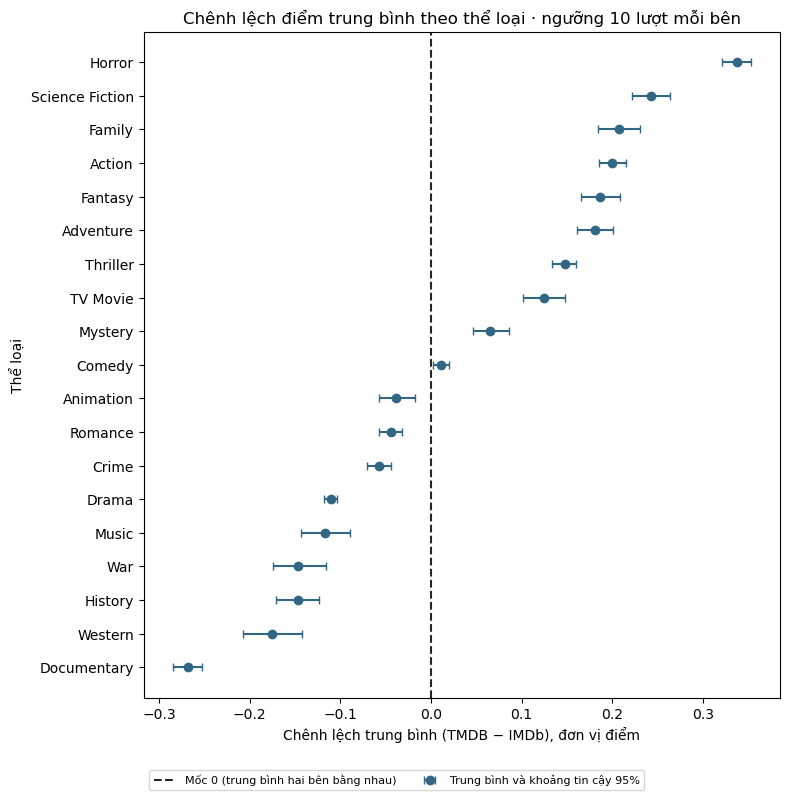

In [8]:
fig, ax = plt.subplots(figsize=(8, 0.34 * len(genre_table) + 1.6))
centres = genre_table["Chênh lệch TB"]
ax.errorbar(centres, genre_table.index,
            xerr=[centres - genre_table["Cận dưới 95%"], genre_table["Cận trên 95%"] - centres],
            fmt="o", color="#316784", capsize=3, label="Trung bình và khoảng tin cậy 95%")
ax.axvline(0, color="#262626", linestyle="--", label="Mốc 0 (trung bình hai bên bằng nhau)")
ax.set(title="Chênh lệch điểm trung bình theo thể loại · ngưỡng 10 lượt mỗi bên",
       xlabel="Chênh lệch trung bình (TMDB − IMDb), đơn vị điểm", ylabel="Thể loại")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.10), fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

#### Nhận xét theo 19 thể loại

Khi so từng phim, **IMDb chấm cao hơn ở nhiều phim hơn trong 11 thể loại**, còn **TMDB chấm cao hơn ở nhiều phim hơn trong 8 thể loại**. Với 17 thể loại, bên thường chấm cao hơn cũng là bên có điểm trung bình cao hơn. Hai trường hợp còn lại là phim hài và phim bí ẩn.

**Chín thể loại mà IMDb thường chấm cao hơn và cũng có điểm trung bình cao hơn**

- **Tài liệu (*Documentary*) và miền Tây (*Western*).** IMDb cao hơn ở khoảng 70% số phim tài liệu và 68% số phim miền Tây. Tính trên tất cả phim trong từng nhóm, điểm IMDb cao hơn TMDB trung bình **0,269 điểm** ở phim tài liệu và **0,175 điểm** ở phim miền Tây. Đây là hai thể loại mà điểm trung bình nghiêng về IMDb rõ nhất.
- **Lịch sử (*History*) và chiến tranh (*War*).** IMDb cao hơn ở khoảng 66% số phim lịch sử và 68% số phim chiến tranh. Hai thể loại có cùng mức chênh sau khi làm tròn: điểm IMDb trung bình cao hơn **0,147 điểm** ở mỗi thể loại.
- **Âm nhạc (*Music*) và chính kịch (*Drama*).** IMDb cao hơn ở khoảng 64% số phim âm nhạc và 63% số phim chính kịch. Tính cả nhóm, điểm IMDb cao hơn trung bình **0,116 điểm** ở phim âm nhạc và **0,111 điểm** ở phim chính kịch.
- **Hình sự (*Crime*), tình cảm (*Romance*) và hoạt hình (*Animation*).** IMDb cao hơn ở khoảng 61% số phim hình sự, 58% số phim tình cảm và 58% số phim hoạt hình. Dù vậy, khi tính trung bình cả nhóm, IMDb chỉ nhỉnh hơn lần lượt **0,057**, **0,045** và **0,039 điểm**. Đặc biệt ở phim hoạt hình, hai điểm của *từng phim* cách nhau trung bình **0,584 điểm**. Khi lấy trung bình cho cả thể loại, các phim lệch về hai phía gần như bù nhau.

**Tám thể loại mà TMDB thường chấm cao hơn và cũng có điểm trung bình cao hơn**

- **Kinh dị (*Horror*) và khoa học viễn tưởng (*Science Fiction*).** TMDB cao hơn ở khoảng 63% số phim kinh dị và 56% số phim khoa học viễn tưởng. Điểm TMDB trung bình cao hơn **0,337 điểm** ở phim kinh dị và **0,243 điểm** ở phim khoa học viễn tưởng. Đây là hai thể loại mà điểm trung bình nghiêng về TMDB rõ nhất.
- **Gia đình (*Family*) và hành động (*Action*).** TMDB cao hơn ở khoảng 54% số phim gia đình và 53% số phim hành động. Điểm TMDB trung bình cao hơn lần lượt **0,208** và **0,200 điểm**. Phim gia đình còn là thể loại có **khoảng cách lớn nhất** khi so từng phim: hai nền tảng chấm cách nhau trung bình **0,642 điểm**.
- **Kỳ ảo (*Fantasy*) và phiêu lưu (*Adventure*).** TMDB cao hơn ở khoảng 54% số phim kỳ ảo và 52% số phim phiêu lưu. Ở cả hai thể loại, mức chênh trung bình đều gần hai phần mười điểm: **0,187 điểm** ở phim kỳ ảo và **0,181 điểm** ở phim phiêu lưu, cùng nghiêng về TMDB.
- **Phim truyền hình lẻ (*TV Movie*) và phim giật gân (*Thriller*).** Ở phim truyền hình lẻ, TMDB cao hơn ở **50,78%** số phim và cao hơn trung bình **0,125 điểm**. Phim giật gân là trường hợp sát nhau nhất về số phim: **49,73%** có điểm TMDB cao hơn, **48,03%** có điểm IMDb cao hơn, còn **2,24%** bằng điểm (các tỷ lệ đã làm tròn). Tính cả nhóm phim giật gân, TMDB cao hơn trung bình **0,148 điểm**.

**Hai thể loại mà IMDb thường chấm cao hơn nhưng TMDB có điểm trung bình cao hơn**

- **Hài (*Comedy*).** IMDb cao hơn ở **54,96%** số phim hài. Tuy nhiên, khi tính trung bình cả nhóm, TMDB nhỉnh hơn **0,011 điểm**. Đây là thể loại có điểm trung bình của hai nền tảng gần nhau nhất.
- **Bí ẩn (*Mystery*).** IMDb cao hơn ở **52,30%** số phim bí ẩn, còn điểm trung bình của TMDB cao hơn **0,065 điểm**. Cũng như với phim hài, TMDB dẫn ở ít phim hơn, nhưng những lần TMDB dẫn có cách biệt đủ lớn để bù lại.

**Khi tra một phim cụ thể**, khoảng cách được tính bằng cách lấy điểm cao hơn trừ điểm thấp hơn. Ví dụ, 7,5 và 7,0 cách nhau **0,5 điểm** dù nền tảng nào chấm 7,5. Theo cách tính này, phim tài liệu và phim kinh dị đều lệch khoảng nửa điểm (**0,527** và **0,581 điểm**). Điều khác nhau là IMDb thường cao hơn với phim tài liệu, còn TMDB thường cao hơn với phim kinh dị.

### 4. Kết quả có đổi nếu mỗi bên phải có ít nhất 100 lượt chấm?

Giữ nguyên các điều kiện ở mục 1 và nâng mức tối thiểu từ 10 lên 100 lượt trên mỗi nền tảng. Trong 77.674 phim ban đầu, **18.056 phim** đạt mức mới và **59.618 phim** bị loại ở bước này. Tỷ lệ phần trăm ở mỗi hàng được tính trên số phim của hàng đó.

In [9]:
q1_100 = q1.loc[q1["vote_count"].ge(100) & q1["numVotes"].ge(100)].copy()
strict_gaps = q1_100["vote_average"] - q1_100["averageRating"]
threshold_table = pd.DataFrame(
    [main_result, rating_summary(strict_gaps)],
    index=pd.Index([10, 100], name="Lượt chấm tối thiểu mỗi bên"),
).astype({"Số phim": int})
display(threshold_table.round(3))

,Số phim,TMDB cao hơn (%),Bằng điểm (%),IMDb cao hơn (%),Chênh lệch TB,Khoảng cách TB,Cận dưới 95%,Cận trên 95%
Lượt chấm tối thiểu mỗi bên,,,,,,,,
10,77674,41.924,2.805,55.271,0.006,0.527,0.001,0.011
100,18056,47.347,1.357,51.296,0.116,0.369,0.108,0.124


Ở cả hai ngưỡng, IMDb đều cao hơn trên một nửa số phim. Khi tăng ngưỡng lên 100 lượt, tỷ lệ này giảm từ **55,27% xuống 51,30%**. Hai điểm cũng gần nhau hơn ở nhóm đạt ngưỡng 100 lượt. Khoảng cách trung bình giảm từ **0,527 xuống 0,369 điểm**.

Nếu xét cả hướng chênh lệch, TMDB cao hơn trung bình **0,116 điểm** ở ngưỡng 100, so với **0,006 điểm** ở ngưỡng 10. Việc nâng ngưỡng đã loại hơn ba phần tư số phim. Đây là so sánh giữa hai nhóm phim trong cùng bản dữ liệu. Muốn biết điểm của một phim thay đổi thế nào khi có thêm người chấm, cần theo dõi phim đó theo thời gian.

### 5. Trả lời Q1

Trong **77.674 phim** có ít nhất 10 lượt chấm trên mỗi nền tảng, **IMDb cao hơn ở khoảng 55 trong 100 phim**. Khi tra cùng một phim ở hai nơi, **hai điểm cách nhau trung bình khoảng 0,53 điểm trên thang 10**. Bên thường cao hơn còn tùy thể loại. Trong mẫu này, IMDb thường cao hơn với phim tài liệu, còn TMDB thường cao hơn với phim kinh dị.

Vì vậy, khi tổng hợp đánh giá cho một phim cụ thể, nên ghi rõ điểm đến từ đâu. Nếu quyết định chọn phim phụ thuộc vào vài phần mười điểm, tra cả hai nguồn sẽ cho biết chúng có cùng ủng hộ lựa chọn đó hay không.

Kết quả chỉ mô tả các phim đáp ứng điều kiện ở mục 1. Những phim ít lượt chấm hoặc có mã trùng có thể có kết quả khác. CSV chỉ có điểm tổng hợp của từng phim, thiếu thông tin về người chấm và thời điểm họ chấm, nên chưa thể giải thích nguyên nhân hai bên cho điểm khác nhau.